# Praktikum 1 - Klasterisasi K-Means pada Dataset Iris

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

Pada praktikum pertama di Jobsheet 4 ini saya mempraktikkan pembuatan model klasterisasi *unsupervised learning* menggunakan algoritma **K-Means** pada dataset `Iris.csv`, memvisualisasikan hasil pengelompokan beserta posisi titik pusat klaster (*centroid*), menghitung nilai *Sum of Squared Errors* (SSE / *inertia*), serta menentukan jumlah klaster ($k$) terbaik menggunakan **Metode Elbow**.

### Langkah 1 - Persiapan Data

Mengimpor library yang dibutuhkan (`pandas`, `numpy`, `matplotlib.pyplot`, `KMeans`) dan memuat dataset `Iris.csv`.

In [1]:
# Persiapan data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('Iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### Langkah 2 - Seleksi Fitur

Memisahkan 4 fitur pengukuran bunga (`SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`) ke dalam variabel `X` dengan membuang kolom `Id` di awal dan kolom `Species` di akhir.

In [2]:
# Seleksi Fitur
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]
X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Langkah 3 - Plot Data Awal

Karena fitur berdimensi 4, visualisasi awal ditampilkan dalam 2 dimensi berdasarkan dua kolom pertama yaitu `SepalLengthCm` (sumbu X) dan `SepalWidthCm` (sumbu Y).

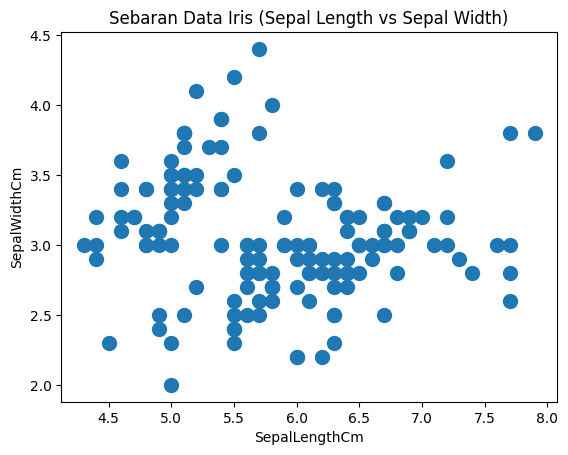

Text(0.5, 1.0, 'Sebaran Data Iris (Sepal Length vs Sepal Width)')

In [3]:
# Plot Data
# Karena data 4 dimensi, maka akan kita coba
# plot cluster berdasarkan Sepal Length dan Sepal Width saja

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.title('Sebaran Data Iris (Sepal Length vs Sepal Width)')

### Langkah 4 - Buat Model K-Means ($k = 2$)

Menginisiasi model `KMeans` dengan percobaan awal `n_clusters=2` (seolah-olah kita belum mengetahui bahwa terdapat 3 spesies asli pada data Iris), lalu melatih dan memprediksi klaster tiap baris data.

In [4]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2 - anggap saja kita tidak tahu jumlah label ada 3 :)
from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2, random_state=42)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

### Langkah 5 - Visualisasi Hasil Klaster dan Centroid ($k = 2$)

Memvisualisasikan hasil pengelompokan K-Means ($k=2$) beserta titik pusat klaster (*centroid*) yang ditandai dengan lingkaran merah berukuran besar.

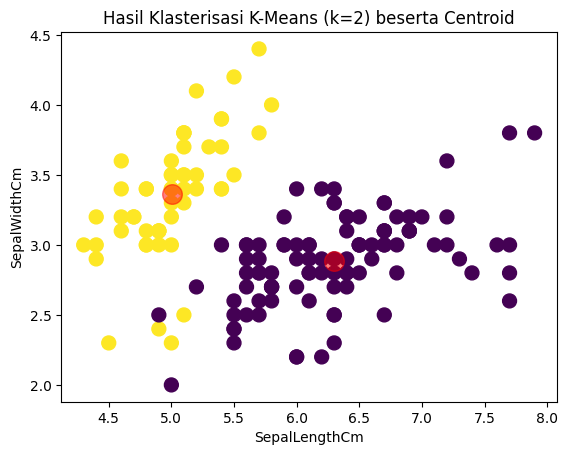

Text(0.5, 1.0, 'Hasil Klasterisasi K-Means (k=2) beserta Centroid')

In [5]:
# Plot hasil cluster berdasarkan Sepal Length dan Sepal Width
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.title('Hasil Klasterisasi K-Means (k=2) beserta Centroid')

### Langkah 6 - Cek Nilai SSE (Inertia)

Mencetak nilai *Sum of Squared Errors* (SSE) atau `inertia_` dari model K-Means dengan $k=2$.

In [6]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733906


### Langkah 7 - Implementasi Metode Elbow

Menjalankan perulangan K-Means untuk nilai $k=1$ sampai $k=9$ guna mencari titik siku (*elbow*) di mana penurunan nilai SSE mulai melandai.

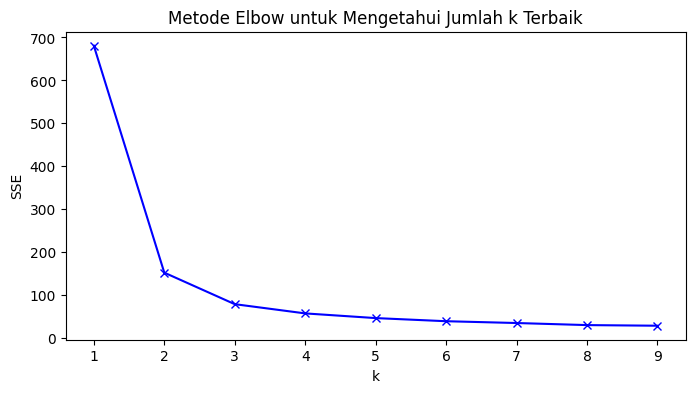

In [7]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1, 10)

# Cek nilai SSE setiap k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

In [8]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8244
k=2; SSE=152.36870647733906
k=3; SSE=78.9450658259773
k=4; SSE=57.440280212954754
k=5; SSE=46.535582051282056
k=6; SSE=39.251830892636775
k=7; SSE=35.042759952465836
k=8; SSE=30.217021122152705
k=9; SSE=28.756456196581205


Dari grafik Metode Elbow dan rincian nilai SSE di atas, terlihat bahwa saat $k$ naik dari $1$ ke $2$, nilai SSE turun sangat tajam dari `680.82` menjadi `152.37`, dan saat naik ke $k=3$ turun signifikan lagi menjadi `78.94`. Setelah melewati titik $k=3$ (misalnya ke $k=4$ dengan SSE `57.32` dan seterusnya), grafik mulai melandai dan penurunan SSE tidak lagi drastis. Oleh karena itu, titik siku (*elbow*) berada pada **$k=3$**, yang sesuai dengan jumlah spesies bunga asli pada dataset Iris (yaitu *Iris-setosa*, *Iris-versicolor*, dan *Iris-virginica*).